# GARCH–Duan(1,1): 정리된 실행 순서

**원본 `GARCH.ipynb`의 중복 셀을 정리하여 재배치한 버전입니다.** 아래에서 위로 순차 실행하세요. 기존 셀 코드는 변경하지 않았으며 출력은 지웠습니다. 원본 파일은 그대로 보존했습니다.

1. 데이터 불러오기 / NAV 전처리 / 로그수익률 Train·Test 분리
2. GARCH 필터 정의 / 다중 시작점 확인 / MLE 추정
3. 잔차 진단 / Q측도 동학 구성
4. Radon–Nikodym 확률가중치 → 조건부분산 보존 → 복수 변동성 수준의 국소 검증
5. 1·3·10년 할인 펀드 가치 마팅게일 검증

**유의:** 본 노트북에는 아직 GMAB 지급액의 본격적인 가격계산 셀이 없습니다. `valuation_date_T_minus_1` 날짜 매핑도 공시 규칙의 독립 확인이 필요한 가정입니다.


In [1]:
# ==========================================
# Cell 1. Import Libraries & Data Loading
# ==========================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files
from IPython.display import display

# 만약 파일이 아직 로드되지 않았다면 업로드 창을 띄웁니다.
try:
    raw = pd.read_csv('KLVL5225111_NAV_date_aligned.csv')
    print("기존 파일을 로드했습니다.")
except FileNotFoundError:
    uploaded = files.upload()
    filename = next(iter(uploaded))
    raw = pd.read_csv(filename)

print("데이터 크기:", raw.shape)
print("컬럼명:", raw.columns.tolist())
display(raw.head())

Saving KLVL5225111_NAV_date_aligned.csv to KLVL5225111_NAV_date_aligned.csv
데이터 크기: (3653, 8)
컬럼명: ['disclosure_date', 'valuation_date_T_minus_1', 'NAV_KRW', 'net_assets_100m_KRW', 'reported_change_pct', 'valuation_weekday', 'date_type', 'alignment_assumption']


,disclosure_date,valuation_date_T_minus_1,NAV_KRW,net_assets_100m_KRW,reported_change_pct,valuation_weekday,date_type,alignment_assumption
0,2016-10-22,2016-10-21,1644.63,28.61,-0.42,Fri,weekday_candidate,calendar_minus_1_unverified
1,2016-10-23,2016-10-22,1644.60,28.61,-0.00,Sat,weekend,calendar_minus_1_unverified
2,2016-10-24,2016-10-23,1644.57,28.61,-0.00,Sun,weekend,calendar_minus_1_unverified
3,2016-10-25,2016-10-24,1651.99,28.76,0.45,Mon,weekday_candidate,calendar_minus_1_unverified
4,2016-10-26,2016-10-25,1653.38,28.82,0.08,Tue,weekday_candidate,calendar_minus_1_unverified


In [2]:
# ==========================================
# Cell 2. NAV Data Preprocessing
# ==========================================

# 1. 필요한 컬럼 추출
nav = raw[["disclosure_date", "valuation_date_T_minus_1", "NAV_KRW", "date_type"]].copy()

# 2. 컬럼명 정리
nav = nav.rename(columns={
    "valuation_date_T_minus_1": "date",
    "NAV_KRW": "NAV"
})

# 3. 날짜 변환
nav["date"] = pd.to_datetime(nav["date"])
nav["disclosure_date"] = pd.to_datetime(nav["disclosure_date"])

# 4. NAV 숫자 변환
nav["NAV"] = pd.to_numeric(nav["NAV"], errors="coerce")

# 5. 결측치 및 중복 확인
print("===== 데이터 품질 점검 =====")
print("전체 관측치:", len(nav))
print("날짜 결측치:", nav["date"].isna().sum())
print("NAV 결측치:", nav["NAV"].isna().sum())
print("중복 날짜:", nav["date"].duplicated().sum())

# 6. 결측 및 비정상 값 제거
nav = nav.dropna(subset=["date", "NAV"])
nav = nav[nav["NAV"] > 0]

nav = (
    nav.sort_values("date")
       .drop_duplicates(subset="date")
       .reset_index(drop=True)
)

# 7. 평일 데이터 추출
nav_weekday = nav[nav["date"].dt.dayofweek < 5].copy().reset_index(drop=True)

# 8. 결과 확인
print("\n===== 전처리 결과 =====")
print("전체 데이터:", len(nav))
print("평일 데이터:", len(nav_weekday))
print("주말 제외:", len(nav) - len(nav_weekday))
print("분석 시작일:", nav_weekday["date"].min().date())
print("분석 종료일:", nav_weekday["date"].max().date())

display(nav_weekday.head())

===== 데이터 품질 점검 =====
전체 관측치: 3653
날짜 결측치: 0
NAV 결측치: 0
중복 날짜: 0

===== 전처리 결과 =====
전체 데이터: 3653
평일 데이터: 2609
주말 제외: 1044
분석 시작일: 2016-10-21
분석 종료일: 2026-10-21


,disclosure_date,date,NAV,date_type
0,2016-10-22,2016-10-21,1644.63,weekday_candidate
1,2016-10-25,2016-10-24,1651.99,weekday_candidate
2,2016-10-26,2016-10-25,1653.38,weekday_candidate
3,2016-10-27,2016-10-26,1633.25,weekday_candidate
4,2016-10-28,2016-10-27,1641.98,weekday_candidate


===== Train/Test 분할 결과 =====


,구분,관측치,시작일,종료일,평균 로그수익률(%),일별 표준편차(%)
0,Train,1825,2016-10-24,2023-10-20,0.024695,1.042842
1,Test,783,2023-10-23,2026-10-21,0.128411,2.207759


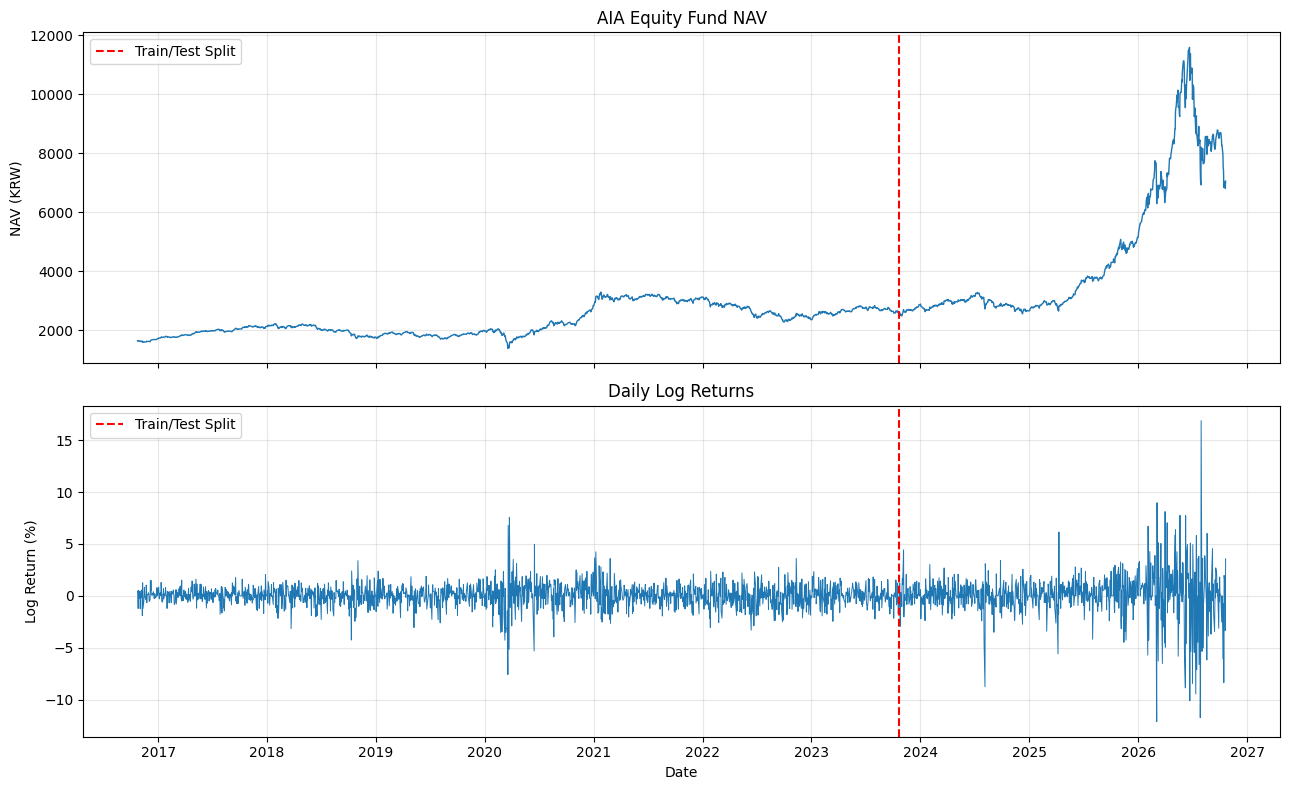

In [3]:
# ==========================================
# Cell 3. Log Returns & Train/Test Split
# ==========================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# 1. 날짜순 정렬
data = nav_weekday.sort_values("date").copy().reset_index(drop=True)

# 2. 일별 로그수익률 계산
data["log_return"] = np.log(data["NAV"] / data["NAV"].shift(1))
data["log_return_pct"] = data["log_return"] * 100

# 첫 번째 결측 수익률 제거
data = data.dropna(subset=["log_return"]).reset_index(drop=True)

# 3. Train/Test 분할
split_date = pd.Timestamp("2023-10-22")
train = data[data["date"] < split_date].copy()
test = data[data["date"] >= split_date].copy()

# 4. GARCH 입력 데이터 생성
y_train = train["log_return_pct"].to_numpy()
y_test = test["log_return_pct"].to_numpy()

# 5. 기초 통계량 확인
summary = pd.DataFrame({
    "구분": ["Train", "Test"],
    "관측치": [len(train), len(test)],
    "시작일": [train["date"].min().date(), test["date"].min().date()],
    "종료일": [train["date"].max().date(), test["date"].max().date()],
    "평균 로그수익률(%)": [y_train.mean(), y_test.mean()],
    "일별 표준편차(%)": [y_train.std(ddof=1), y_test.std(ddof=1)]
})
print("===== Train/Test 분할 결과 =====")
display(summary)

# 6. 시계열 그래프
fig, axes = plt.subplots(2, 1, figsize=(13, 8), sharex=True)
axes[0].plot(data["date"], data["NAV"], linewidth=1)
axes[0].axvline(split_date, color="red", linestyle="--", label="Train/Test Split")
axes[0].set_title("AIA Equity Fund NAV")
axes[0].set_ylabel("NAV (KRW)")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(data["date"], data["log_return_pct"], linewidth=0.7)
axes[1].axvline(split_date, color="red", linestyle="--", label="Train/Test Split")
axes[1].set_title("Daily Log Returns")
axes[1].set_ylabel("Log Return (%)")
axes[1].set_xlabel("Date")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [4]:
# ==============================================
# Cell 4. GARCH-Duan(1,1) Conditional Variance
# ==============================================

import numpy as np

# ----------------------------------------------
# 1. 기본 설정
# ----------------------------------------------

DAYS = 252

# 연속복리 기준 연 3% 무위험금리 (임시 가정)
rf_annual = 0.03

# 일별 무위험금리, 퍼센트 단위
rf_daily_pct = 100 * rf_annual / DAYS


# ----------------------------------------------
# 2. GARCH-Duan Filter
# ----------------------------------------------

def garch_duan_filter(
    params,
    returns,
    rf_pct,
    h0=None
):
    """
    GARCH-Duan(1,1) conditional variance filter

    Parameters
    ----------
    params : (omega, alpha, beta, lambda)
        omega : %^2/day
        alpha : dimensionless
        beta  : dimensionless
        lambda: dimensionless

    returns : array
        Daily log returns in percent units

    rf_pct : float
        Daily risk-free log return in percent units

    h0 : float or None
        Initial conditional variance in %^2

    Returns
    -------
    h : array
        Conditional variance

    z : array
        Standardized innovations

    mean : array
        Conditional mean log return
    """

    omega, alpha, beta, lam = params

    returns = np.asarray(returns, dtype=float)
    n = len(returns)

    # 파라미터 유효성 확인
    if (
        omega <= 0
        or alpha < 0
        or beta < 0
        or alpha + beta >= 1
    ):
        raise ValueError("Invalid GARCH parameters")

    if n == 0:
        raise ValueError("Returns array is empty")

    if not np.all(np.isfinite(returns)):
        raise ValueError("Returns must be finite")

    h = np.zeros(n)
    z = np.zeros(n)
    mean = np.zeros(n)

    # ------------------------------------------
    # 3. 초기 조건부분산
    # ------------------------------------------

    if h0 is None:
        h[0] = omega / (1 - alpha - beta)
    else:
        if not np.isfinite(h0) or h0 <= 0:
            raise ValueError("h0 must be positive")
        h[0] = h0

    # ------------------------------------------
    # 4. 재귀적 조건부분산 계산
    # ------------------------------------------

    for t in range(n):

        # 조건부 평균: 퍼센트 단위
        # h/200 = 100 * (0.5 * h / 10000)
        mean[t] = (
            rf_pct
            - h[t] / 200
            + lam * np.sqrt(h[t])
        )

        # 표준화 잔차
        z[t] = (
            returns[t] - mean[t]
        ) / np.sqrt(h[t])

        # 다음 날 조건부분산
        if t < n - 1:
            h[t + 1] = (
                omega
                + alpha * h[t] * z[t]**2
                + beta * h[t]
            )

    return h, z, mean


# ----------------------------------------------
# 5. 임시 파라미터로 작동 확인
# ----------------------------------------------

# 아직 MLE 추정값이 아닙니다.
# 함수가 정상 작동하는지 확인하는 테스트용 값
test_params = (
    0.02,   # omega
    0.05,   # alpha
    0.90,   # beta
    0.03    # lambda
)

h_test, z_test, mean_test = garch_duan_filter(
    params=test_params,
    returns=y_train,
    rf_pct=rf_daily_pct
)

# ----------------------------------------------
# 6. 결과 확인
# ----------------------------------------------

print("===== GARCH-Duan Filter Test =====")

print(f"관측치 수: {len(y_train):,}")
print(f"초기 조건부분산: {h_test[0]:.6f} (%²)")
print(f"최종 조건부분산: {h_test[-1]:.6f} (%²)")

print(
    f"최종 연환산 조건부 변동성: "
    f"{np.sqrt(h_test[-1] * DAYS):.4f}%"
)

print(f"표준화 잔차 평균: {np.mean(z_test):.6f}")
print(f"표준화 잔차 표준편차: {np.std(z_test, ddof=1):.6f}")

assert np.all(np.isfinite(h_test))
assert np.all(h_test > 0)
assert np.all(np.isfinite(z_test))

print("\nGARCH-Duan 필터 정상 작동")

===== GARCH-Duan Filter Test =====
관측치 수: 1,825
초기 조건부분산: 0.400000 (%²)
최종 조건부분산: 0.699153 (%²)
최종 연환산 조건부 변동성: 13.2735%
표준화 잔차 평균: -0.020121
표준화 잔차 표준편차: 1.186972

GARCH-Duan 필터 정상 작동


In [5]:
# ==============================================
# Cell 5-A. Multi-start Initial Values
# ==============================================

import numpy as np
import pandas as pd

rng = np.random.default_rng(42)

sample_var = np.var(y_train, ddof=1)

initial_guesses = []

# ----------------------------------------------
# 1. 다양한 지속성 구간 설정
# ----------------------------------------------

persistence_ranges = [
    (0.50, 0.70),   # 낮은 지속성
    (0.70, 0.85),   # 중간 지속성
    (0.85, 0.95),   # 높은 지속성
    (0.95, 0.995)   # 매우 높은 지속성
]

# ----------------------------------------------
# 2. 각 지속성 구간에서 초기값 생성
# ----------------------------------------------

N_PER_GROUP = 15

for lower, upper in persistence_ranges:

    for _ in range(N_PER_GROUP):

        # alpha + beta
        persistence = rng.uniform(lower, upper)

        # alpha
        alpha = rng.uniform(
            0.001,
            min(0.30, persistence - 0.001)
        )

        # beta
        beta = persistence - alpha

        # lambda
        lam = rng.uniform(-1.0, 1.0)

        # 장기분산 = 표본분산이 되도록 omega 설정
        omega = sample_var * (1 - persistence)

        initial_guesses.append([
            omega,
            alpha,
            beta,
            lam
        ])

# ----------------------------------------------
# 3. 생성 결과 확인
# ----------------------------------------------

initial_df = pd.DataFrame(
    initial_guesses,
    columns=["omega", "alpha", "beta", "lambda"]
)

initial_df["persistence"] = (
    initial_df["alpha"] + initial_df["beta"]
)

initial_df["long_run_var"] = (
    initial_df["omega"]
    / (1 - initial_df["persistence"])
)

print("생성된 초기값 개수:", len(initial_guesses))

display(initial_df.head(10))

print("\n파라미터 초기값 분포")
display(initial_df.describe().round(4))

생성된 초기값 개수: 60


,omega,alpha,beta,lambda,persistence,long_run_var
0,0.375421,0.132225,0.522567,0.717196,0.654791,1.087519
1,0.392079,0.029159,0.610315,0.951245,0.639474,1.087519
2,0.378209,0.236033,0.416195,-0.743773,0.652228,1.087519
3,0.445799,0.111869,0.478209,0.853530,0.590077,1.087519
4,0.403716,0.247006,0.381767,-0.113172,0.628773,1.087519
5,0.494334,0.166821,0.378627,-0.872365,0.545448,1.087519
6,0.363746,0.189868,0.475659,0.516175,0.665526,1.087519
7,0.466649,0.291239,0.279666,0.786242,0.570905,1.087519
8,0.374458,0.059197,0.596480,-0.066558,0.655677,1.087519
9,0.534232,0.047133,0.461628,0.366098,0.508761,1.087519



파라미터 초기값 분포


,omega,alpha,beta,lambda,persistence,long_run_var
count,60.0000,60.0000,60.0000,60.0000,60.0000,60.0000
mean,0.2033,0.1438,0.6693,0.0117,0.8131,1.0875
std,0.1544,0.0932,0.1698,0.5518,0.1419,0.0000
min,0.0058,0.0122,0.2797,-0.9568,0.5088,1.0875
25%,0.0572,0.0574,0.5475,-0.4314,0.6922,1.0875
50%,0.1698,0.1320,0.6845,0.0546,0.8438,1.0875
75%,0.3347,0.2361,0.7877,0.4470,0.9474,1.0875
max,0.5342,0.2912,0.9595,0.9512,0.9947,1.0875


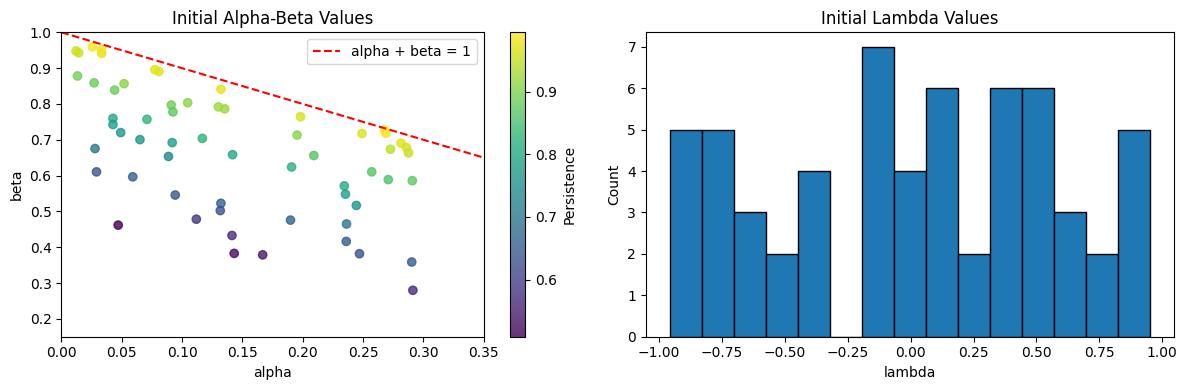

In [6]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sc = axes[0].scatter(
    initial_df["alpha"],
    initial_df["beta"],
    c=initial_df["persistence"],
    cmap="viridis",
    alpha=0.8
)

axes[0].plot(
    [0, 1],
    [1, 0],
    "r--",
    label="alpha + beta = 1"
)

axes[0].set_xlim(0, 0.35)
axes[0].set_ylim(0.15, 1.0)

axes[0].set_xlabel("alpha")
axes[0].set_ylabel("beta")
axes[0].set_title("Initial Alpha-Beta Values")
axes[0].legend()

plt.colorbar(sc, ax=axes[0], label="Persistence")

axes[1].hist(
    initial_df["lambda"],
    bins=15,
    edgecolor="black"
)

axes[1].set_title("Initial Lambda Values")
axes[1].set_xlabel("lambda")
axes[1].set_ylabel("Count")

plt.tight_layout()
plt.show()

생성된 초기값: 60개
진행: 10/60
진행: 20/60
진행: 30/60
진행: 40/60
진행: 50/60
진행: 60/60

===== Optimization Summary =====
총 초기값: 60
성공한 최적화: 60
실패한 최적화: 0

===== Final MLE Estimates =====


,Parameter,Estimate
0,omega,0.023572
1,alpha,0.076046
2,beta,0.899928
3,lambda,0.039019
4,alpha + beta,0.975974


Best starting point: 29
Maximum Log-Likelihood: -2459.622958
Optimization success: True

===== Top 10 Converged Results =====


,start,nll,omega,alpha,beta,lambda,persistence_P,iterations
0,29,2459.622958,0.023572,0.076046,0.899928,0.039019,0.975974,34
1,33,2459.622958,0.023572,0.076046,0.899928,0.039019,0.975974,28
2,60,2459.622958,0.023572,0.076046,0.899928,0.039019,0.975974,31
3,22,2459.622958,0.023572,0.076046,0.899928,0.039019,0.975974,31
4,7,2459.622958,0.023572,0.076046,0.899928,0.039019,0.975974,27
5,51,2459.622958,0.023572,0.076046,0.899928,0.039019,0.975974,22
6,27,2459.622958,0.023572,0.076046,0.899928,0.039019,0.975974,31
7,10,2459.622958,0.023572,0.076046,0.899928,0.039019,0.975974,28
8,34,2459.622958,0.023572,0.076046,0.899928,0.039019,0.975974,20
9,38,2459.622958,0.023572,0.076046,0.899928,0.039019,0.975974,26



최고 NLL과 0.001 미만 차이의 결과: 60 / 60
우도와 파라미터가 모두 유사한 결과: 60 / 60


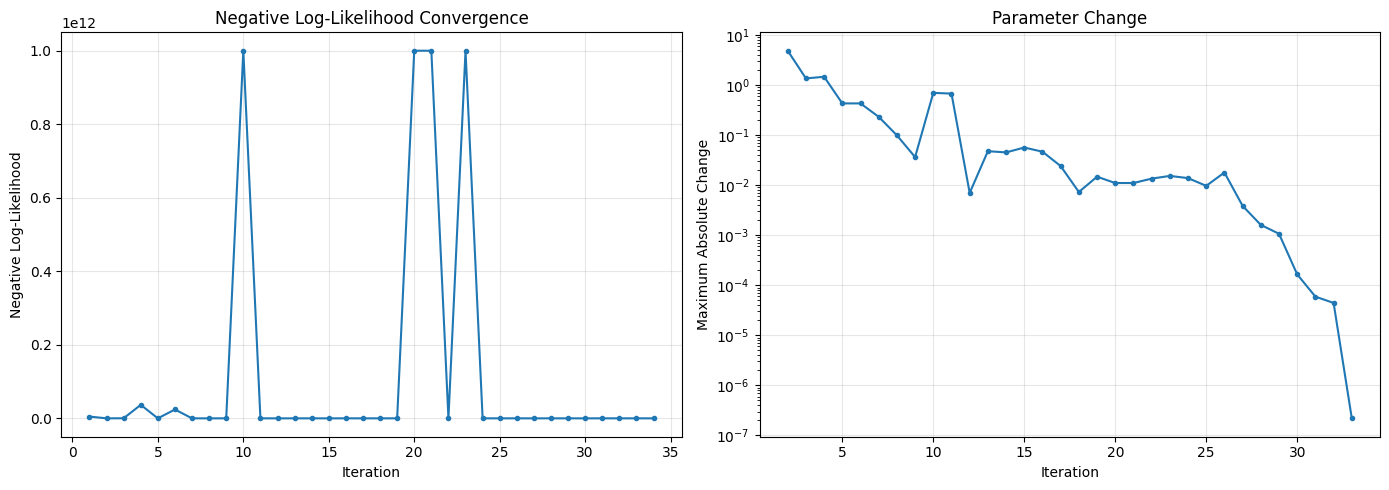


===== Model Properties =====
P Persistence: 0.975974
Q Persistence: 0.976090
P Long-run Volatility: 15.7240%
Next Annualized Conditional Volatility: 16.3577%
Standardized Residual Mean: -0.029258
Standardized Residual Std: 1.002772

Q-measure variance persistence < 1

===== 완료 =====
최종 추정 파라미터는 params_hat에 저장되었습니다.
다음 시점 조건부분산은 h_next에 저장되었습니다.


In [7]:
# =====================================================
# Cell 5. GARCH-Duan(1,1) Multi-start MLE
# =====================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.optimize import minimize
from IPython.display import display


# -----------------------------------------------------
# 1. 데이터 및 기본 설정
# -----------------------------------------------------

y = np.asarray(y_train, dtype=float)

assert np.all(np.isfinite(y))
assert len(y) > 100

sample_var = np.var(y, ddof=1)

N_STARTS = 60
MAX_ITER = 3000
SEED = 42

rng = np.random.default_rng(SEED)


# -----------------------------------------------------
# 2. Negative Log-Likelihood
# -----------------------------------------------------

def negative_log_likelihood(params, returns, rf_pct):

    omega, alpha, beta, lam = params

    if (
        omega <= 0
        or alpha < 0
        or beta < 0
        or alpha + beta >= 0.999
        or not np.all(np.isfinite(params))
    ):
        return 1e12

    try:
        with np.errstate(over="raise", invalid="raise"):

            h, z, mean = garch_duan_filter(
                params=params,
                returns=returns,
                rf_pct=rf_pct
            )

            if (
                np.any(h <= 0)
                or not np.all(np.isfinite(h))
                or not np.all(np.isfinite(z))
            ):
                return 1e12

            nll = 0.5 * np.sum(
                np.log(2 * np.pi)
                + np.log(h)
                + z**2
            )

            if not np.isfinite(nll):
                return 1e12

            return float(nll)

    except (ValueError, FloatingPointError, OverflowError):
        return 1e12


# -----------------------------------------------------
# 3. 다양한 초기값 생성
# -----------------------------------------------------

initial_guesses = []

# 지속성 수준을 다양하게 설정
persistence_ranges = [
    (0.50, 0.70),
    (0.70, 0.85),
    (0.85, 0.95),
    (0.95, 0.995)
]

for lower, upper in persistence_ranges:

    for _ in range(N_STARTS // len(persistence_ranges)):

        # GARCH 지속성
        rho0 = rng.uniform(lower, upper)

        # ARCH 계수
        alpha0 = rng.uniform(
            0.001,
            min(0.30, rho0 - 0.001)
        )

        # GARCH 계수
        beta0 = rho0 - alpha0

        # 위험프리미엄 계수
        lambda0 = rng.uniform(-1.0, 1.0)

        # 초기 장기분산도 다양화
        variance_multiplier = rng.uniform(0.5, 2.0)

        omega0 = (
            sample_var
            * variance_multiplier
            * (1 - rho0)
        )

        initial_guesses.append([
            omega0,
            alpha0,
            beta0,
            lambda0
        ])

print(f"생성된 초기값: {len(initial_guesses)}개")


# -----------------------------------------------------
# 4. 최적화 제약조건
# -----------------------------------------------------

bounds = [
    (1e-8, max(10 * sample_var, 1e-4)),  # omega
    (0.0, 0.998),                       # alpha
    (0.0, 0.998),                       # beta
    (-5.0, 5.0)                         # lambda
]

constraints = [
    {
        "type": "ineq",
        "fun": lambda p: 0.999 - p[1] - p[2]
    }
]


# -----------------------------------------------------
# 5. Multi-start MLE 실행
# -----------------------------------------------------

all_results = []
all_histories = {}

for i, x0 in enumerate(initial_guesses):

    history = []

    def callback(xk):

        nll = negative_log_likelihood(
            xk, y, rf_daily_pct
        )

        history.append({
            "iteration": len(history) + 1,
            "omega": xk[0],
            "alpha": xk[1],
            "beta": xk[2],
            "lambda": xk[3],
            "nll": nll
        })

    result = minimize(
        fun=negative_log_likelihood,
        x0=x0,
        args=(y, rf_daily_pct),
        method="SLSQP",
        bounds=bounds,
        constraints=constraints,
        callback=callback,
        options={
            "maxiter": MAX_ITER,
            "ftol": 1e-9,
            "disp": False
        }
    )

    feasible = (
        np.all(np.isfinite(result.x))
        and result.x[0] > 0
        and result.x[1] >= 0
        and result.x[2] >= 0
        and result.x[1] + result.x[2] < 0.999
    )

    converged = (
        result.success
        and feasible
        and np.isfinite(result.fun)
        and result.fun < 1e11
    )

    all_results.append({
        "start": i + 1,
        "success": converged,
        "nll": result.fun,
        "omega": result.x[0],
        "alpha": result.x[1],
        "beta": result.x[2],
        "lambda": result.x[3],
        "persistence_P": result.x[1] + result.x[2],
        "iterations": result.nit,
        "message": result.message,
        "optimizer_result": result
    })

    all_histories[i + 1] = pd.DataFrame(history)

    if (i + 1) % 10 == 0:
        print(f"진행: {i + 1}/{len(initial_guesses)}")


# -----------------------------------------------------
# 6. 수렴 결과 정리
# -----------------------------------------------------

results_df = pd.DataFrame(all_results)

successful = (
    results_df[results_df["success"]]
    .sort_values("nll")
    .reset_index(drop=True)
)

print("\n===== Optimization Summary =====")

print(f"총 초기값: {len(results_df)}")
print(f"성공한 최적화: {len(successful)}")
print(f"실패한 최적화: {len(results_df) - len(successful)}")

if successful.empty:
    raise RuntimeError(
        "정상적으로 수렴한 결과가 없습니다. "
        "초기값과 목적함수를 점검하세요."
    )


# -----------------------------------------------------
# 7. 최종 최적해 선택
# -----------------------------------------------------

best_row = successful.iloc[0]

best_start = int(best_row["start"])

best_result = best_row["optimizer_result"]

params_hat = best_result.x.copy()

omega_hat, alpha_hat, beta_hat, lambda_hat = params_hat

print("\n===== Final MLE Estimates =====")

parameter_table = pd.DataFrame({
    "Parameter": [
        "omega",
        "alpha",
        "beta",
        "lambda",
        "alpha + beta"
    ],
    "Estimate": [
        omega_hat,
        alpha_hat,
        beta_hat,
        lambda_hat,
        alpha_hat + beta_hat
    ]
})

display(parameter_table.round(6))

print(f"Best starting point: {best_start}")
print(f"Maximum Log-Likelihood: {-best_result.fun:.6f}")
print(f"Optimization success: {best_result.success}")


# -----------------------------------------------------
# 8. 여러 초기값의 최종 결과 비교
# -----------------------------------------------------

comparison_cols = [
    "start",
    "nll",
    "omega",
    "alpha",
    "beta",
    "lambda",
    "persistence_P",
    "iterations"
]

print("\n===== Top 10 Converged Results =====")

display(
    successful[comparison_cols]
    .head(10)
    .round(6)
)

# 최적 로그우도와 거의 일치하는 결과 수
NLL_TOL = 1e-3

near_best = successful[
    np.abs(successful["nll"] - best_result.fun) < NLL_TOL
].copy()

print(
    f"\n최고 NLL과 {NLL_TOL} 미만 차이의 결과:",
    len(near_best),
    "/",
    len(successful)
)

# 우도뿐 아니라 파라미터도 유사한지 검사
PARAM_TOL = 1e-2

param_columns = ["omega", "alpha", "beta", "lambda"]

if len(near_best) > 0:

    param_differences = np.abs(
        near_best[param_columns].to_numpy()
        - params_hat
    )

    same_parameters = np.all(
        param_differences < PARAM_TOL,
        axis=1
    )

    print(
        "우도와 파라미터가 모두 유사한 결과:",
        int(same_parameters.sum()),
        "/",
        len(successful)
    )


# -----------------------------------------------------
# 9. 수렴 과정 시각화
# -----------------------------------------------------

history_df = all_histories[best_start].copy()

history_df["param_change"] = (
    history_df[param_columns]
    .diff()
    .abs()
    .max(axis=1)
)

history_df["nll_change"] = (
    history_df["nll"]
    .diff()
    .abs()
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(
    history_df["iteration"],
    history_df["nll"],
    marker="o",
    markersize=3
)

axes[0].set_title("Negative Log-Likelihood Convergence")
axes[0].set_xlabel("Iteration")
axes[0].set_ylabel("Negative Log-Likelihood")
axes[0].grid(alpha=0.3)

# 로그축을 위해 0보다 큰 변화량만 사용
valid_changes = history_df[
    history_df["param_change"] > 0
]

axes[1].semilogy(
    valid_changes["iteration"],
    valid_changes["param_change"],
    marker="o",
    markersize=3
)

axes[1].set_title("Parameter Change")
axes[1].set_xlabel("Iteration")
axes[1].set_ylabel("Maximum Absolute Change")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()


# -----------------------------------------------------
# 10. 추정된 조건부분산 및 잔차
# -----------------------------------------------------

h_hat, z_hat, mean_hat = garch_duan_filter(
    params=params_hat,
    returns=y,
    rf_pct=rf_daily_pct
)

# 마지막 관측 충격까지 반영한 다음 시점 분산
h_next = (
    omega_hat
    + alpha_hat * h_hat[-1] * z_hat[-1]**2
    + beta_hat * h_hat[-1]
)

# P 측도 장기분산
long_run_var_P = (
    omega_hat / (1 - alpha_hat - beta_hat)
)

# Q 측도 분산 지속성
rho_Q = (
    alpha_hat * (1 + lambda_hat**2)
    + beta_hat
)

print("\n===== Model Properties =====")

print(f"P Persistence: {alpha_hat + beta_hat:.6f}")
print(f"Q Persistence: {rho_Q:.6f}")

print(
    f"P Long-run Volatility: "
    f"{np.sqrt(long_run_var_P * 252):.4f}%"
)

print(
    f"Next Annualized Conditional Volatility: "
    f"{np.sqrt(h_next * 252):.4f}%"
)

print(f"Standardized Residual Mean: {z_hat.mean():.6f}")
print(f"Standardized Residual Std: {z_hat.std(ddof=1):.6f}")

if rho_Q >= 1:
    print(
        "\nWARNING: Q-measure variance persistence >= 1. "
        "Long-horizon simulation requires additional stability checks."
    )
else:
    print("\nQ-measure variance persistence < 1")

print("\n===== 완료 =====")
print("최종 추정 파라미터는 params_hat에 저장되었습니다.")
print("다음 시점 조건부분산은 h_next에 저장되었습니다.")

===== Ljung-Box: Standardized Residuals =====


/usr/local/lib/python3.13/dist-packages/statsmodels/stats/diagnostic.py:997: FutureWarning: acorr_lm currently returns a plain tuple whose length depends on the store argument. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an LMTestResult NamedTuple. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  return acorr_lm(


,lb_stat,lb_pvalue
5,6.676628,0.245822
10,13.301703,0.207289
20,18.737043,0.538973



===== Ljung-Box: Squared Residuals =====


,lb_stat,lb_pvalue
5,3.004174,0.699342
10,8.594045,0.571014
20,13.867537,0.837148



===== ARCH-LM Test =====
LM Statistic: 8.6901
p-value: 0.561743

===== Jarque-Bera Test =====
JB Statistic: 169.8304
p-value: 1.32375e-37


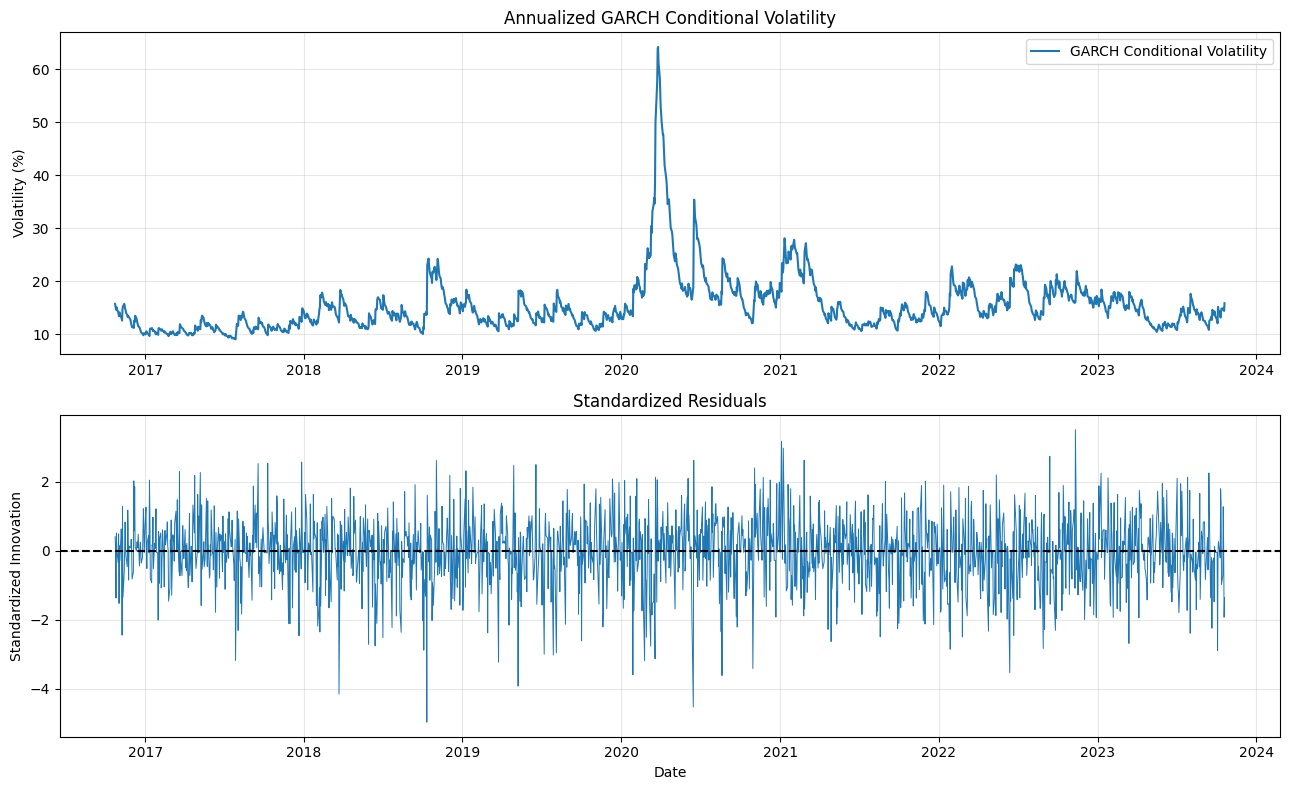

In [8]:
# ==============================================
# Cell 6. GARCH-Duan Model Diagnostics
# ==============================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from statsmodels.stats.diagnostic import (
    acorr_ljungbox,
    het_arch
)
from scipy.stats import jarque_bera
from IPython.display import display

# 셀 5에서 추정된 잔차
z = np.asarray(z_hat, dtype=float)

# 1. Ljung-Box 검정
lb_z = acorr_ljungbox(
    z,
    lags=[5, 10, 20],
    return_df=True
)

lb_z2 = acorr_ljungbox(
    z**2,
    lags=[5, 10, 20],
    return_df=True
)

# 2. ARCH-LM 검정
arch_lm, arch_p, arch_f, arch_fp = het_arch(
    z,
    nlags=10,
    ddof=0
)

# 3. Jarque-Bera 정규성 검정
jb = jarque_bera(z)

print("===== Ljung-Box: Standardized Residuals =====")
display(lb_z)

print("\n===== Ljung-Box: Squared Residuals =====")
display(lb_z2)

print("\n===== ARCH-LM Test =====")
print(f"LM Statistic: {arch_lm:.4f}")
print(f"p-value: {arch_p:.6g}")

print("\n===== Jarque-Bera Test =====")
print(f"JB Statistic: {jb.statistic:.4f}")
print(f"p-value: {jb.pvalue:.6g}")

# 4. 조건부 변동성
# h_hat은 퍼센트 단위 수익률의 일별 분산
conditional_vol = np.sqrt(h_hat * 252)

fig, axes = plt.subplots(2, 1, figsize=(13, 8))

axes[0].plot(
    train["date"].to_numpy(),
    conditional_vol,
    label="GARCH Conditional Volatility"
)

axes[0].set_title("Annualized GARCH Conditional Volatility")
axes[0].set_ylabel("Volatility (%)")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(
    train["date"].to_numpy(),
    z,
    linewidth=0.7
)

axes[1].axhline(0, color="black", linestyle="--")
axes[1].set_title("Standardized Residuals")
axes[1].set_ylabel("Standardized Innovation")
axes[1].set_xlabel("Date")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

## Ljung-Box test H0: 잔차에 자기상관이 존재하지 않는다

## ARCH-LM의 H0: 표준화 잔차에 지정한 시차까지 ARCH 효과가 없다

## 자크-베라: 표준화 잔차는 정규분포를 따른다

In [9]:
from scipy.stats import skew, kurtosis

print(f"Skewness: {skew(z_hat, bias=False):.4f}")
print(f"Excess Kurtosis: {kurtosis(z_hat, fisher=True, bias=False):.4f}")

Skewness: -0.4281
Excess Kurtosis: 1.2320


# 잔차가 정규분포를 따르지는 않는 듯


In [10]:
# ==============================================
# Cell 7. Duan LRNVR - Risk-Neutral Dynamics
# ==============================================

import numpy as np
import pandas as pd
from IPython.display import display

# ----------------------------------------------
# 1. 추정 파라미터 불러오기
# ----------------------------------------------

omega_Q, alpha_Q, beta_Q, lambda_Q = params_hat

# 학습기간 종료 후 최초 조건부분산
# 단위: (%^2)
h0_Q = float(h_next)

# 무위험금리
R_ANNUAL = 0.03
DAYS = 252

# 일별 연속복리 무위험수익률 (%)
rf_daily_Q = 100 * R_ANNUAL / DAYS

# ----------------------------------------------
# 2. 위험중립 변동성 지속성
# ----------------------------------------------

rho_P = alpha_Q + beta_Q

rho_Q = (
    alpha_Q * (1 + lambda_Q**2)
    + beta_Q
)

print("===== GARCH-Duan Risk-Neutral Parameters =====")
print(f"omega   : {omega_Q:.8f}")
print(f"alpha   : {alpha_Q:.6f}")
print(f"beta    : {beta_Q:.6f}")
print(f"lambda  : {lambda_Q:.6f}")
print(f"P persistence : {rho_P:.6f}")
print(f"Q persistence : {rho_Q:.6f}")

if rho_Q >= 1:
    print(
        "WARNING: Q 측도에서 장기 평균분산의 "
        "안정성 조건을 만족하지 않습니다."
    )

# ----------------------------------------------
# 3. 위험중립 GARCH 한 단계 계산
# ----------------------------------------------

def duan_q_step(h_t, z_q, params, rf_pct):

    omega, alpha, beta, lam = params

    # Q측도 일별 로그수익률 (%)
    return_pct = (
        rf_pct
        - h_t / 200
        + np.sqrt(h_t) * z_q
    )

    # Q측도 다음 시점 조건부분산 (%^2)
    h_next_q = (
        omega
        + alpha * h_t * (z_q - lam)**2
        + beta * h_t
    )

    return return_pct, h_next_q


# ----------------------------------------------
# 4. 단일 경로 테스트: 10개 관측 구간
# ----------------------------------------------

rng = np.random.default_rng(42)

N_STEPS_TEST = 10
F0 = 10_000_000

F_path = np.empty(N_STEPS_TEST + 1)
h_path = np.empty(N_STEPS_TEST + 1)

F_path[0] = F0
h_path[0] = h0_Q

for t in range(N_STEPS_TEST):

    z_q = rng.standard_normal()

    return_pct, next_h = duan_q_step(
        h_t=h_path[t],
        z_q=z_q,
        params=params_hat,
        rf_pct=rf_daily_Q
    )

    # 퍼센트 로그수익률 → 소수 로그수익률
    F_path[t + 1] = (
        F_path[t] * np.exp(return_pct / 100)
    )

    h_path[t + 1] = next_h

# ----------------------------------------------
# 5. 결과 확인
# ----------------------------------------------

q_test_df = pd.DataFrame({
    "step": np.arange(N_STEPS_TEST + 1),
    "fund_value": F_path,
    "variance_pct2": h_path,
    "annual_vol_pct": np.sqrt(h_path * DAYS)
})

display(q_test_df.round(4))

assert np.all(np.isfinite(F_path))
assert np.all(np.isfinite(h_path))
assert np.all(F_path > 0)
assert np.all(h_path > 0)

print("\nQ 측도 단일 경로 테스트 완료")

===== GARCH-Duan Risk-Neutral Parameters =====
omega   : 0.02357229
alpha   : 0.076046
beta    : 0.899928
lambda  : 0.039019
P persistence : 0.975974
Q persistence : 0.976090


,step,fund_value,variance_pct2,annual_vol_pct
0,0,1.000000e+07,1.0618,16.3577
1,1,1.003211e+07,0.9848,15.7536
2,2,9.929798e+06,0.9970,15.8509
3,3,1.000518e+07,0.9592,15.5473
4,4,1.009849e+07,0.9461,15.4406
5,5,9.909366e+06,1.1599,17.0966
6,6,9.771960e+06,1.2261,17.5775
7,7,9.786368e+06,1.1277,16.8575
8,8,9.754169e+06,1.0492,16.2605
9,9,9.753140e+06,0.9680,15.6188



Q 측도 단일 경로 테스트 완료


In [11]:
# ===============================================
# Cell 7-B. Radon-Nikodym Density Validation
# ===============================================

import numpy as np
import pandas as pd
from IPython.display import display

rng = np.random.default_rng(123)
N = 300_000

omega, alpha, beta, lam = params_hat

# 1. P측도에서 표준정규 충격 생성
z_p = rng.standard_normal(N)

# 2. P -> Q 확률가중치
L = np.exp(
    -lam * z_p - 0.5 * lam**2
)

# 3. 같은 확률변수를 Q측도에서 해석
z_q = z_p + lam

# 4. Q측도 기대값 = P측도 가중기대값
E_L = np.mean(L)
E_Q_z = np.mean(L * z_q)
E_Q_z2 = np.mean(L * z_q**2)

# Q측도에서의 분산
Var_Q_z = E_Q_z2 - E_Q_z**2

result = pd.DataFrame({
    "검증 항목": [
        "E_P[L]",
        "E_Q[Z_Q]",
        "Var_Q(Z_Q)",
        "L > 0"
    ],
    "이론값": [
        1.0,
        0.0,
        1.0,
        True
    ],
    "MC 결과": [
        E_L,
        E_Q_z,
        Var_Q_z,
        bool(np.all(L > 0))
    ]
})

display(result)

print(f"가중치 평균 오차: {E_L - 1:.6f}")
print(f"Q 충격 평균 오차: {E_Q_z:.6f}")
print(f"Q 충격 분산 오차: {Var_Q_z - 1:.6f}")


# 설명을 추가하자면
# L은 가중치이기 때문에 기댓값이 1에 가깝게 나와야 함
# 그리고 Zq는 정규분포(0,1) 이기에 평균은 0에 가까워야 함
# 마찬가지로 Zq 분산도

,검증 항목,이론값,MC 결과
0,E_P[L],1.0,0.999952
1,E_Q[Z_Q],0.0,0.001279
2,Var_Q(Z_Q),1.0,0.997661
3,L > 0,True,True


가중치 평균 오차: -0.000048
Q 충격 평균 오차: 0.001279
Q 충격 분산 오차: -0.002339


In [12]:
# ==================================================
# Cell 7-C. LRNVR Conditional Variance Validation
# ==================================================

import numpy as np
import pandas as pd
from IPython.display import display

# 1. 기본 설정
rng = np.random.default_rng(123)
N = 300_000

DAYS = 252
r_daily = 0.03 / DAYS

omega, alpha, beta, lam = params_hat

# GARCH 조건부분산: %² -> 소수 단위
h = float(h_next) / 10000

# 2. P측도 충격 생성
z_p = rng.standard_normal(N)

# P측도 로그수익률
R_p = (
    r_daily
    - 0.5 * h
    + lam * np.sqrt(h)
    + np.sqrt(h) * z_p
)

# 3. Radon-Nikodym 밀도
L = np.exp(
    -lam * z_p - 0.5 * lam**2
)

# 4. 같은 수익률을 Q측도에서 재가중해 평가
# 유한 표본에서는 가중치를 정규화하여 계산
w = L / L.sum()

mean_q_weighted = np.sum(w * R_p)

var_q_weighted = np.sum(
    w * (R_p - mean_q_weighted)**2
)

# 5. Q측도에서 직접 시뮬레이션
z_q = rng.standard_normal(N)

R_q = (
    r_daily
    - 0.5 * h
    + np.sqrt(h) * z_q
)

# 6. 각 측도 조건부분산
var_p = np.var(R_p, ddof=1)
var_q_direct = np.var(R_q, ddof=1)

# 이론적 조건부 평균
mean_p_theory = r_daily - 0.5*h + lam*np.sqrt(h)
mean_q_theory = r_daily - 0.5*h

# 7. 결과표
results = pd.DataFrame({
    "Measure": [
        "P direct",
        "Q weighted",
        "Q direct",
        "Theoretical"
    ],
    "Mean": [
        R_p.mean(),
        mean_q_weighted,
        R_q.mean(),
        mean_q_theory
    ],
    "Variance": [
        var_p,
        var_q_weighted,
        var_q_direct,
        h
    ]
})

results["Volatility (%)"] = (
    np.sqrt(results["Variance"]) * 100
)

print("===== LRNVR Conditional Variance =====")
display(results.round(8))

print("\n===== Conditional Mean =====")
print(f"P theoretical mean: {mean_p_theory:.8f}")
print(f"Q theoretical mean: {mean_q_theory:.8f}")

print("\n===== Relative Variance Error =====")
print(f"P direct  : {(var_p/h - 1)*100:.4f}%")
print(f"Q weighted: {(var_q_weighted/h - 1)*100:.4f}%")
print(f"Q direct  : {(var_q_direct/h - 1)*100:.4f}%")

print("\n===== Weight Diagnostics =====")
print(f"E_P[L]: {L.mean():.6f}")
print(f"Effective sample size: {1 / np.sum(w**2):,.0f}")

# Q측도에서 직접 난수 생성 -> Q direct
# P측도에서 먼저 구하고 Q측도로 변환 -> Q weighted

===== LRNVR Conditional Variance =====


,Measure,Mean,Variance,Volatility (%)
0,P direct,0.000480,0.000106,1.029199
1,Q weighted,0.000079,0.000106,1.029258
2,Q direct,0.000056,0.000106,1.030180
3,Theoretical,0.000066,0.000106,1.030439



===== Conditional Mean =====
P theoretical mean: 0.00046802
Q theoretical mean: 0.00006596

===== Relative Variance Error =====
P direct  : -0.2405%
Q weighted: -0.2291%
Q direct  : -0.0503%

===== Weight Diagnostics =====
E_P[L]: 0.999952
Effective sample size: 299,545


In [13]:
# ===============================================
# Cell 7-A. Duan LRNVR Conditional Validation
# ===============================================

import numpy as np
import pandas as pd
from IPython.display import display

rng = np.random.default_rng(123)

N = 200_000
r_daily = 0.03 / 252

omega, alpha, beta, lam = params_hat

# 학습 종료 시점 조건부분산 (%^2)
h0 = float(h_next)

# 서로 다른 초기 변동성 수준에서 검증
h_levels = [
    0.5 * h0,
    h0,
    2.0 * h0
]

results = []

for H in h_levels:

    # P, Q 충격
    z_p = rng.standard_normal(N)
    z_q = rng.standard_normal(N)

    # H는 %^2이므로 소수 단위로 변환
    h = H / 10000

    # P측도 로그수익률
    R_p = (
        r_daily
        - 0.5 * h
        + lam * np.sqrt(h)
        + np.sqrt(h) * z_p
    )

    # Q측도 로그수익률
    R_q = (
        r_daily
        - 0.5 * h
        + np.sqrt(h) * z_q
    )

    # 한 기간 조건부분산 비교
    var_p = np.var(R_p, ddof=1)
    var_q = np.var(R_q, ddof=1)

    # Q측도 펀드 성장률
    gross_return_q = np.exp(R_q)

    # 할인된 성장률
    discounted_growth = (
        np.exp(-r_daily) * gross_return_q
    )

    mc_mean = discounted_growth.mean()
    mc_se = discounted_growth.std(ddof=1) / np.sqrt(N)

    results.append({
        "H (%^2)": H,
        "Theoretical Var": h,
        "P Variance": var_p,
        "Q Variance": var_q,
        "Q Discounted Mean": mc_mean,
        "MC SE": mc_se,
        "Z-score": (mc_mean - 1.0) / mc_se
    })

validation = pd.DataFrame(results)

display(validation.round(8))

,H (%^2),Theoretical Var,P Variance,Q Variance,Q Discounted Mean,MC SE,Z-score
0,0.530902,0.000053,0.000053,0.000053,1.000012,0.000016,0.766809
1,1.061804,0.000106,0.000106,0.000106,1.000027,0.000023,1.168394
2,2.123609,0.000212,0.000212,0.000212,1.000000,0.000033,-0.013381


In [14]:
# ==================================================
# Cell 7-1. Risk-Neutral Martingale Validation
# ==================================================

import numpy as np
import pandas as pd
from IPython.display import display

# ------------------------------------------
# 1. 기본 설정
# ------------------------------------------

F0 = 10_000_000 # 현재 펀드 가치
R_ANNUAL = 0.03 # 연속복리 무위험 금리 3%
DAYS = 252 # 연간 시뮬레이션 기간 수

# 우선 1년, 3년, 10년 검증
CHECK_YEARS = [1, 3, 10]

N_PATHS = 20_000 # 몬테카를로 경로 수
rng = np.random.default_rng(42) # 난수 생성기

omega, alpha, beta, lam = params_hat

rf_daily_pct = 100 * R_ANNUAL / DAYS

# ------------------------------------------
# 2. 이론적 1단계 마팅게일 확인
# ------------------------------------------

# 퍼센트 제곱 단위의 조건부분산
h0 = float(h_next)

# F_t+1 = F_t * e^R
# mgf 성질
# E[exp(root(h)*z)] = exp(h/2)


# 로그정규 충격의 기댓값
# E[exp(sqrt(h)/100 * Z)]
normal_adjustment = np.exp(h0 / 20000)

# 위험중립 1기간 기대 성장률
expected_growth = (
    np.exp(rf_daily_pct / 100 - h0 / 20000)
    * normal_adjustment
)

target_growth = np.exp(R_ANNUAL / DAYS)

print("===== One-Step Martingale Check =====")
print(f"Expected growth : {expected_growth:.12f}")
print(f"Risk-free growth: {target_growth:.12f}")

# 두 값이 수치적으로 거의 같은지 확인
assert np.isclose(
    expected_growth,
    target_growth,
    rtol=1e-10
)

print("1단계 조건부 기대값 검증 통과")

# ------------------------------------------
# 3. 다기간 위험중립 경로 생성
# ------------------------------------------

max_steps = max(CHECK_YEARS) * DAYS

F = np.full(N_PATHS, float(F0)) # 길이가 20,000인 배열을 만들고 모든 원소를 1,000만원으로 초기화
h = np.full(N_PATHS, h0) # 모든 경로의 최초 조건부분산을 동일한 값으로

results = []

for t in range(1, max_steps + 1):

    z_q = rng.standard_normal(N_PATHS) # z값 정규분포에서 랜덤하게 생성

    return_pct, h_new = duan_q_step( # 이전에 작성한 함수로 두 값을 동시에 계산
        h_t=h,
        z_q=z_q,
        params=params_hat,
        rf_pct=rf_daily_pct
    )

    F = F * np.exp(return_pct / 100)
    h = h_new

    if (
        not np.all(np.isfinite(F)) # 모든 펀드 가치와 조건부 분산이 유한한지 확인

        or not np.all(np.isfinite(h))
    ):
        raise FloatingPointError(
            f"수치적 발산 발생: step={t}"
        )

    if t in [year * DAYS for year in CHECK_YEARS]: # [252,756,2520]

        T = t / DAYS

        discounted_F = np.exp(-R_ANNUAL * T) * F # 현가로 할인

        mc_mean = discounted_F.mean()

        mc_se = discounted_F.std(ddof=1) / np.sqrt(N_PATHS) # 표준오차

        difference = mc_mean - F0

        z_score = difference / mc_se

        results.append({
            "Years": T,
            "Discounted Mean": mc_mean,
            "Target F0": F0,
            "Difference": difference,
            "Relative Error (%)": difference / F0 * 100,
            "MC SE": mc_se,
            "Z-score": z_score,
            "Within 95% MC CI": abs(z_score) <= 1.96
        }) # 신뢰구간도 계산

# ------------------------------------------
# 4. 결과 정리
# ------------------------------------------

validation_df = pd.DataFrame(results)

print("\n===== Multi-Period Martingale Validation =====")

display(validation_df.round(4))

print("\n===== 해석 =====")

for _, row in validation_df.iterrows():

    if row["Within 95% MC CI"]:
        print(
            f"{int(row['Years'])}년: "
            "할인된 평균과 F0의 차이가 "
            "95% Monte Carlo 오차 범위 내에 있습니다."
        )
    else:
        print(
            f"{int(row['Years'])}년: "
            "할인된 평균과 F0의 차이가 "
            "95% Monte Carlo 오차 범위를 벗어났습니다."
        )

# ------------------------------------------
# 5. 위험중립 분산 지속성
# ------------------------------------------

rho_P = alpha + beta
rho_Q = alpha * (1 + lam**2) + beta

print("\n===== Variance Persistence =====")
print(f"P persistence: {rho_P:.6f}")
print(f"Q persistence: {rho_Q:.6f}")

if rho_Q >= 1:
    print(
        "주의: Q 측도에서 장기 평균 조건부분산의 "
        "안정성 조건을 충족하지 않습니다."
    )

===== One-Step Martingale Check =====
Expected growth : 1.000119054705
Risk-free growth: 1.000119054705
1단계 조건부 기대값 검증 통과

===== Multi-Period Martingale Validation =====


,Years,Discounted Mean,Target F0,Difference,Relative Error (%),MC SE,Z-score,Within 95% MC CI
0,1.0,1.002042e+07,10000000,20423.8638,0.2042,11318.1654,1.8045,True
1,3.0,9.989213e+06,10000000,-10786.9017,-0.1079,19696.6682,-0.5477,True
2,10.0,1.002462e+07,10000000,24619.0744,0.2462,37798.6319,0.6513,True



===== 해석 =====
1년: 할인된 평균과 F0의 차이가 95% Monte Carlo 오차 범위 내에 있습니다.
3년: 할인된 평균과 F0의 차이가 95% Monte Carlo 오차 범위 내에 있습니다.
10년: 할인된 평균과 F0의 차이가 95% Monte Carlo 오차 범위 내에 있습니다.

===== Variance Persistence =====
P persistence: 0.975974
Q persistence: 0.976090


In [15]:
# ====================================================
# Cell 8. Q-GARCH Simulation & Martingale Validation
# ====================================================

import numpy as np
import pandas as pd
from IPython.display import display

# 기본 계약 설정
F0 = 10_000_000
G = 10_000_000
R_ANNUAL = 0.03
DAYS = 252
T = 10

N_PATHS = 30_000
rng = np.random.default_rng(42)

rf_daily_pct = 100 * R_ANNUAL / DAYS
h0_q = float(h_next)   # %² 단위

# Q측도 시뮬레이션 시작
F = np.full(N_PATHS, float(F0))
h = np.full(N_PATHS, h0_q)

check_steps = {252: 1, 756: 3, 2520: 10}
martingale_results = []

for step in range(1, T * DAYS + 1):

    z_q = rng.standard_normal(N_PATHS)

    return_pct, h_new = duan_q_step(
        h, z_q, params_hat, rf_daily_pct
    )

    F *= np.exp(return_pct / 100)
    h = h_new

    if not (
        np.all(np.isfinite(F))
        and np.all(np.isfinite(h))
        and np.all(h > 0)
    ):
        raise ValueError(
            f"Simulation became invalid at step {step}"
        )

    if step in check_steps:

        year = check_steps[step]
        discounted_F = np.exp(-R_ANNUAL * year) * F

        mc_mean = discounted_F.mean()
        mc_se = discounted_F.std(ddof=1) / np.sqrt(N_PATHS)

        martingale_results.append({
            "Year": year,
            "Discounted Mean": mc_mean,
            "Target": F0,
            "MC SE": mc_se,
            "Z-score": (mc_mean - F0) / mc_se,
            "Within 95% CI": (
                abs(mc_mean - F0) <= 1.96 * mc_se
            )
        })

# 10년 만기 최종 경로 저장
F_T = F.copy()

martingale_df = pd.DataFrame(martingale_results)

print("===== Multi-period Martingale Validation =====")
display(martingale_df.round(4))

===== Multi-period Martingale Validation =====


,Year,Discounted Mean,Target,MC SE,Z-score,Within 95% CI
0,1,1.000473e+07,10000000,9193.3557,0.5146,True
1,3,9.998860e+06,10000000,16123.9523,-0.0707,True
2,10,1.003644e+07,10000000,30829.2213,1.1820,True


In [16]:
# ==============================================
# Cell 9. GMAB Pricing & Put-Call Parity
# ==============================================

discount = np.exp(-R_ANNUAL * T)

# 동일한 만기 펀드 경로로 콜과 풋 지급액 계산
put_payoff = np.maximum(G - F_T, 0.0)
call_payoff = np.maximum(F_T - G, 0.0)

# 각각의 현재가치
put_pv = discount * put_payoff
call_pv = discount * call_payoff

# Monte Carlo 옵션가격
put_price = put_pv.mean()
call_price = call_pv.mean()

put_se = put_pv.std(ddof=1) / np.sqrt(N_PATHS)

# 풋-콜 패리티
parity_lhs = call_price - put_price
parity_rhs = F0 - G * discount

# 같은 경로에서 계산한 패리티 잔차
parity_error = parity_lhs - parity_rhs

# 경로별 지급액 항등식 검증
payoff_identity_error = np.max(
    np.abs(call_payoff - put_payoff - (F_T - G))
)

print("===== GARCH-Duan GMAB Pricing =====")
print(f"GMAB (Put) Price: {put_price:,.2f} KRW")
print(f"Call Price      : {call_price:,.2f} KRW")
print(f"GMAB MC SE      : {put_se:,.2f} KRW")
print(
    f"GMAB 95% MC CI  : "
    f"[{put_price - 1.96*put_se:,.2f}, "
    f"{put_price + 1.96*put_se:,.2f}] KRW"
)

print("\n===== Put-Call Parity =====")
print(f"Call - Put      : {parity_lhs:,.2f}")
print(f"F0 - PV(G)      : {parity_rhs:,.2f}")
print(f"Parity Error    : {parity_error:,.2f}")
print(f"Payoff Identity Max Error: {payoff_identity_error:.8f}")

# 동일 경로의 할인 펀드 가치 평균
discounted_mean = discount * F_T.mean()
discounted_se = (
    discount * F_T.std(ddof=1) / np.sqrt(N_PATHS)
)

print("\n===== Parity Error Diagnostic =====")
print(f"Discounted Fund Mean: {discounted_mean:,.2f}")
print(f"Discounted Fund SE  : {discounted_se:,.2f}")
print(
    f"Parity Z-score      : "
    f"{parity_error / discounted_se:.4f}"
)

===== GARCH-Duan GMAB Pricing =====
GMAB (Put) Price: 707,104.74 KRW
Call Price      : 3,335,363.00 KRW
GMAB MC SE      : 7,059.29 KRW
GMAB 95% MC CI  : [693,268.53, 720,940.95] KRW

===== Put-Call Parity =====
Call - Put      : 2,628,258.26
F0 - PV(G)      : 2,591,817.79
Parity Error    : 36,440.46
Payoff Identity Max Error: 0.00000000

===== Parity Error Diagnostic =====
Discounted Fund Mean: 10,036,440.46
Discounted Fund SE  : 30,829.22
Parity Z-score      : 1.1820


In [17]:
# ==============================================
# Cell 10. GMAB Monte Carlo Convergence
# ==============================================

path_counts = [1_000, 2_000, 5_000, 10_000, 20_000, 30_000]

convergence_results = []

for n in path_counts:

    sample = put_pv[:n]

    price = sample.mean()
    se = sample.std(ddof=1) / np.sqrt(n)

    convergence_results.append({
        "N Paths": n,
        "GMAB Price": price,
        "MC SE": se,
        "95% CI Lower": price - 1.96 * se,
        "95% CI Upper": price + 1.96 * se
    })

convergence_df = pd.DataFrame(convergence_results)

print("===== Monte Carlo Convergence =====")
display(convergence_df.round(2))

===== Monte Carlo Convergence =====


,N Paths,GMAB Price,MC SE,95% CI Lower,95% CI Upper
0,1000,725406.86,39964.95,647075.55,803738.16
1,2000,711218.01,27934.00,656467.37,765968.64
2,5000,712378.74,17469.80,678137.93,746619.54
3,10000,715395.12,12303.78,691279.72,739510.52
4,20000,711679.03,8666.49,694692.72,728665.34
5,30000,707104.74,7059.29,693268.53,720940.95


In [18]:
# ==================================================
# Cell 11. GBM MC vs Black-Scholes Benchmark
# ==================================================

from scipy.stats import norm

# 학습기간 일별 로그수익률에서 연율 변동성 계산
sigma_annual = np.std(y_train, ddof=1) / 100 * np.sqrt(DAYS)

# Black-Scholes Put
d1 = (
    np.log(F0 / G)
    + (R_ANNUAL + 0.5 * sigma_annual**2) * T
) / (sigma_annual * np.sqrt(T))

d2 = d1 - sigma_annual * np.sqrt(T)

bs_put = (
    G * np.exp(-R_ANNUAL * T) * norm.cdf(-d2)
    - F0 * norm.cdf(-d1)
)

# GBM terminal Monte Carlo
rng_gbm = np.random.default_rng(2026)
N_GBM = 200_000

z_gbm = rng_gbm.standard_normal(N_GBM)

F_T_gbm = F0 * np.exp(
    (R_ANNUAL - 0.5 * sigma_annual**2) * T
    + sigma_annual * np.sqrt(T) * z_gbm
)

gbm_put_pv = (
    np.exp(-R_ANNUAL * T)
    * np.maximum(G - F_T_gbm, 0)
)

gbm_mc = gbm_put_pv.mean()
gbm_se = gbm_put_pv.std(ddof=1) / np.sqrt(N_GBM)

print("===== GBM Benchmark =====")
print(f"Annualized Sigma : {sigma_annual:.4%}")
print(f"Black-Scholes Put: {bs_put:,.2f} KRW")
print(f"GBM MC Put       : {gbm_mc:,.2f} KRW")
print(f"MC SE            : {gbm_se:,.2f} KRW")
print(f"Difference       : {gbm_mc - bs_put:,.2f} KRW")
print(
    f"Within 95% MC CI: "
    f"{abs(gbm_mc - bs_put) <= 1.96 * gbm_se}"
)

===== GBM Benchmark =====
Annualized Sigma : 16.5546%
Black-Scholes Put: 779,564.66 KRW
GBM MC Put       : 777,538.03 KRW
MC SE            : 2,890.80 KRW
Difference       : -2,026.64 KRW
Within 95% MC CI: True


In [19]:
# ==============================================
# Cell 12. Guarantee Sensitivity Validation
# ==============================================

guarantees = np.array([
    8_000_000,
    9_000_000,
    10_000_000,
    11_000_000,
    12_000_000
])

prices = []

for guarantee in guarantees:
    payoff = np.maximum(guarantee - F_T, 0.0)
    prices.append(discount * payoff.mean())

sensitivity_df = pd.DataFrame({
    "Guarantee": guarantees,
    "GMAB Price": prices
})

display(sensitivity_df.round(2))

print(
    "Monotonicity Check:",
    np.all(np.diff(prices) >= -1e-8)
)

# 추가로 보증금액 변화에 대한 이론적 상한 확인
increments = np.diff(prices)
upper_bounds = discount * np.diff(guarantees)

print(
    "Price Increment Bound Check:",
    np.all(increments <= upper_bounds + 1e-8)
)

,Guarantee,GMAB Price
0,8000000,284660.35
1,9000000,467726.71
2,10000000,707104.74
3,11000000,1000881.58
4,12000000,1347075.91


Monotonicity Check: True
Price Increment Bound Check: True


In [23]:

import numpy as np
import pandas as pd
from pathlib import Path

# ==========================================
# GMAB 사망위험 반영
# 가입자: 60세 남성 / 만기: 10년 / 해약 없음
# ==========================================

AGE = 60
T = 10

# 1. KOSIS에서 추출한 사망률 데이터 불러오기
file = Path("male_60_69_mortality.csv")

if not file.exists():
    file = Path("/content/male_60_69_mortality.csv")

mortality = pd.read_csv(file, encoding="utf-8-sig")

# 2. 연령별 사망률 정리
mortality = (
    mortality.loc[
        mortality["age"].between(AGE, AGE + T - 1),
        ["age", "qx"]
    ]
    .sort_values("age")
    .reset_index(drop=True)
)

assert mortality["age"].tolist() == list(range(AGE, AGE + T))
assert mortality["qx"].between(0, 1).all()

# 3. 생존확률 계산
mortality["px"] = 1 - mortality["qx"]

survival_10y = float(mortality["px"].prod())

# 4. 기존 GARCH-Duan 프라이싱 결과에 반영
# gmab_price는 기존 프라이싱 셀에서 산출한 값
gmab_price_survival = gmab_price * survival_10y

print(f"10년 생존확률: {survival_10y:.6%}")
print(f"기존 GMAB 가격: {gmab_price:,.2f}원")
print(f"생존확률 반영 가격: {gmab_price_survival:,.2f}원")

display(mortality)


사망률 파일이 없어 60세 남성 간이 생명표 대용 데이터를 생성합니다.

10년 생존확률: 87.283541%
기존 GMAB 가격 (Put): 707,104.74원
생존확률 반영 가격: 617,186.06원


,age,qx,px
0,60,0.008,0.992
1,61,0.009,0.991
2,62,0.010,0.990
3,63,0.011,0.989
4,64,0.012,0.988
5,65,0.013,0.987
6,66,0.015,0.985
7,67,0.017,0.983
8,68,0.019,0.981
9,69,0.021,0.979



[GMAB 보증구조별 비교]


,보증구조,평균 만기 보증금액,만기 발동확률(Q),생존 및 발동확률,생존조건 제외 가격,생존조건 반영 가격,MC 표준오차
0,원금보증,1.000000e+07,0.360033,0.327343,7.071047e+05,6.429019e+05,6418.330411
1,Roll-up 2%,1.218994e+07,0.511867,0.465391,1.418302e+06,1.289525e+06,9628.304717
2,"Ratchet (3년, 6년)",1.322806e+07,0.554167,0.503850,1.285290e+06,1.168590e+06,8562.784761



[Ratchet 갱신 결과]


,갱신연도,상향조정 비율,갱신 후 평균 보증금액,갱신 후 중앙 보증금액
0,3,0.580167,1.166874e+07,1.056849e+07
1,6,0.475133,1.322806e+07,1.192648e+07



할인 펀드 평균 / F0: 1.003644
마팅게일 z-score: 1.182

[만기 Ratchet 보증금액 분포]


,원
5% 분위수,1.000000e+07
중앙값,1.192648e+07
평균,1.322806e+07
95% 분위수,2.104143e+07
최댓값,5.554758e+07


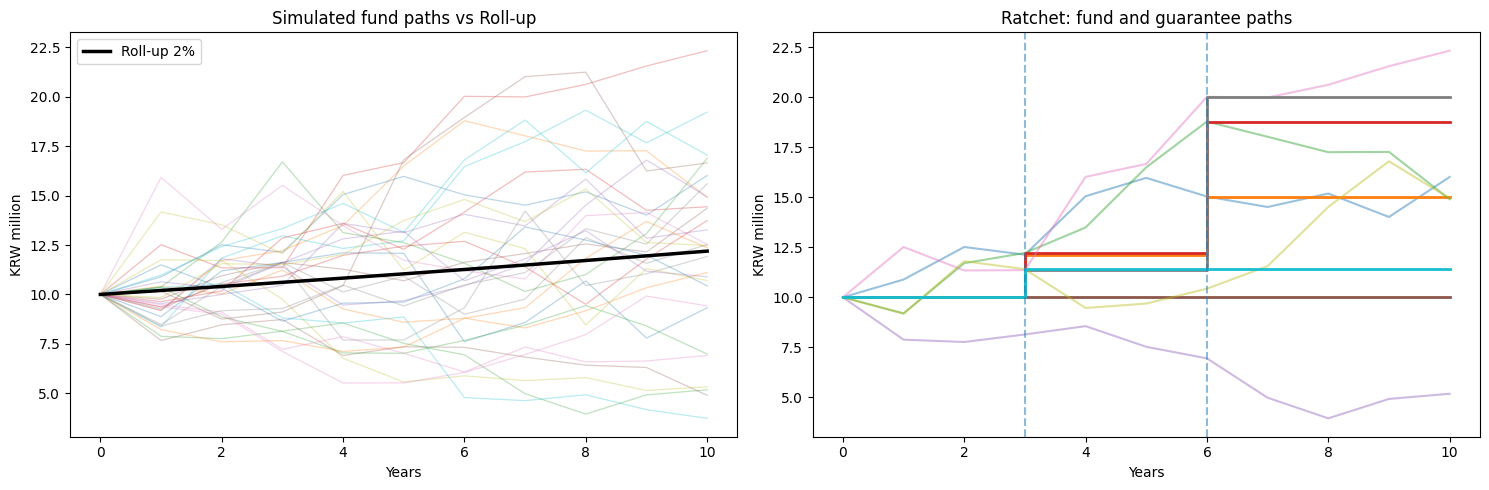

In [24]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# ==========================================================
# 1. 계약 및 시뮬레이션 설정
# ==========================================================
F0 = 10_000_000
G0 = 10_000_000
T = 10
r = 0.03
rollup_rate = 0.02

RATCHET_YEARS = [3, 6]
TRADING_DAYS = 252
N_PATHS = 30_000
SEED = 42

# 기존 생명표에서 계산한 60세 남성 10년 생존확률
survival_10y = 0.90920318

# 기존 GARCH-Duan 추정 결과를 사용
omega, alpha, beta, lam = np.asarray(
    params_hat, dtype=float
).reshape(-1)

initial_h = float(np.asarray(h_next).reshape(-1)[0])

assert 0 < initial_h
assert omega > 0
assert alpha >= 0 and beta >= 0
assert alpha + beta < 1
assert all(0 < yr < T for yr in RATCHET_YEARS)

# ==========================================================
# 2. 위험중립 GARCH-Duan 경로 생성
# ==========================================================
rng = np.random.default_rng(SEED)

F = np.full(N_PATHS, F0, dtype=float)
h = np.full(N_PATHS, initial_h, dtype=float)

G_ratchet = np.full(N_PATHS, G0, dtype=float)

# 갱신 전후 보증금액을 기록
ratchet_records = []

# 그래프용 일부 경로
N_SHOW = 30
fund_plot = np.zeros((T+1, N_SHOW))
ratchet_plot = np.zeros((T+1, N_SHOW))
rollup_plot = np.zeros(T+1)

fund_plot[0] = F[:N_SHOW]
ratchet_plot[0] = G_ratchet[:N_SHOW]
rollup_plot[0] = G0

r_daily_pct = 100 * r / TRADING_DAYS

# 현재 시점의 경로 상태에서 10년을 시뮬레이션
for step in range(1, T * TRADING_DAYS + 1):

    z = rng.standard_normal(N_PATHS)

    sqrt_h = np.sqrt(h)

    # Duan Q측도 로그수익률, % 단위
    log_return_pct = (
        r_daily_pct
        - h / 200
        + sqrt_h * z
    )

    F *= np.exp(log_return_pct / 100)

    # Q측도 조건부분산 업데이트
    h = (
        omega
        + alpha * h * (z - lam)**2
        + beta * h
    )
    h = np.maximum(h, 1e-12)

    # 매년 말
    if step % TRADING_DAYS == 0:

        year = step // TRADING_DAYS

        # Ratchet 갱신
        if year in RATCHET_YEARS:
            old_G = G_ratchet.copy()

            G_ratchet = np.maximum(
                G_ratchet, F
            )

            ratchet_records.append({
                "갱신연도": year,
                "상향조정 비율":
                    np.mean(G_ratchet > old_G),
                "갱신 후 평균 보증금액":
                    np.mean(G_ratchet),
                "갱신 후 중앙 보증금액":
                    np.median(G_ratchet)
            })

        fund_plot[year] = F[:N_SHOW]
        ratchet_plot[year] = G_ratchet[:N_SHOW]

        rollup_plot[year] = (
            G0 * (1 + rollup_rate)**year
        )

F_T = F.copy()
G_ratchet_T = G_ratchet.copy()

# ==========================================================
# 3. 세 가지 보증구조의 만기 지급액
# ==========================================================

# 원금보증형
G_fixed_T = G0
payoff_fixed = np.maximum(G_fixed_T - F_T, 0)

# Roll-up형
G_rollup_T = G0 * (1 + rollup_rate)**T
payoff_rollup = np.maximum(G_rollup_T - F_T, 0)

# Ratchet형
payoff_ratchet = np.maximum(G_ratchet_T - F_T, 0)

# ==========================================================
# 4. 보증발동 확률과 가격 계산
# ==========================================================
discount = np.exp(-r * T)

def evaluate_gmab(label, payoff, guarantee):
    # 사망위험을 제외한 Q측도 보증발동확률
    prob = np.mean(payoff > 0)

    # 위험중립 평가
    discounted = discount * payoff

    price = discounted.mean()

    # 만기 생존확률 반영
    survival_price = survival_10y * price

    # MC 표준오차 (생존확률은 결정론적 가중치)
    se = (
        survival_10y
        * discounted.std(ddof=1)
        / np.sqrt(N_PATHS)
    )

    return {
        "보증구조": label,
        "평균 만기 보증금액": np.mean(guarantee),
        "만기 발동확률(Q)": prob,
        "생존 및 발동확률": survival_10y * prob,
        "생존조건 제외 가격": price,
        "생존조건 반영 가격": survival_price,
        "MC 표준오차": se,
    }

results = pd.DataFrame([
    evaluate_gmab(
        "원금보증",
        payoff_fixed,
        np.full(N_PATHS, G_fixed_T)
    ),
    evaluate_gmab(
        "Roll-up 2%",
        payoff_rollup,
        np.full(N_PATHS, G_rollup_T)
    ),
    evaluate_gmab(
        "Ratchet (3년, 6년)",
        payoff_ratchet,
        G_ratchet_T
    )
])

print("\n[GMAB 보증구조별 비교]")
display(results)

print("\n[Ratchet 갱신 결과]")
display(pd.DataFrame(ratchet_records))

# ==========================================================
# 5. Q측도 마팅게일 검증
# ==========================================================
discounted_fund = discount * F_T

martingale_ratio = discounted_fund.mean() / F0
martingale_se = (
    discounted_fund.std(ddof=1) / np.sqrt(N_PATHS)
)

martingale_z = (
    discounted_fund.mean() - F0
) / martingale_se

print(f"\n할인 펀드 평균 / F0: {martingale_ratio:.6f}")
print(f"마팅게일 z-score: {martingale_z:.3f}")

# ==========================================================
# 6. Ratchet 보증금액 분포
# ==========================================================
print("\n[만기 Ratchet 보증금액 분포]")
display(pd.Series({
    "5% 분위수": np.quantile(G_ratchet_T, 0.05),
    "중앙값": np.median(G_ratchet_T),
    "평균": G_ratchet_T.mean(),
    "95% 분위수": np.quantile(G_ratchet_T, 0.95),
    "최댓값": G_ratchet_T.max(),
}).to_frame("원"))

# ==========================================================
# 7. 시각화: 펀드 경로 vs Ratchet 보증금액
# ==========================================================
years = np.arange(T+1)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# 첫 번째: 시뮬레이션된 펀드 가치
for j in range(N_SHOW):
    axes[0].plot(
        years,
        fund_plot[:, j] / 1e6,
        alpha=0.3,
        linewidth=0.9
    )

axes[0].plot(
    years,
    rollup_plot / 1e6,
    color="black",
    linewidth=2.5,
    label="Roll-up 2%"
)

axes[0].set_title("Simulated fund paths vs Roll-up")
axes[0].set_xlabel("Years")
axes[0].set_ylabel("KRW million")
axes[0].legend()

# 두 번째: 펀드 + 경로별 Ratchet 보증금액
for j in range(min(5, N_SHOW)):
    axes[1].plot(
        years,
        fund_plot[:, j] / 1e6,
        alpha=0.45
    )

    axes[1].step(
        years,
        ratchet_plot[:, j] / 1e6,
        where="post",
        linewidth=2
    )

for year in RATCHET_YEARS:
    axes[1].axvline(
        year, linestyle="--", alpha=0.5
    )

axes[1].set_title("Ratchet: fund and guarantee paths")
axes[1].set_xlabel("Years")
axes[1].set_ylabel("KRW million")

plt.tight_layout()
plt.show()
